# An agent live behind a runtime endpoint, with cost and latency dashboards

**Outcome:** the agent is **live on a runtime** (a service you can call), and you can **see its cost and latency on dashboards**.

**How it works, in five lines**
1. The agent is wrapped in a small web service with an endpoint: `POST /v1/agent:invoke` (plus `/health` and `/metrics`).
2. **Guardrails** run *before* the agent (reject oversized input, stop when the budget is used up).
3. **Hooks** run *after* every request and record its latency, tokens and cost.
4. We send traffic to it and read a **dashboard** built from those records (numbers, a text view and charts).
5. A **release gate** (like a CI check) passes or fails the deployment against limits for latency, cost and errors.

| Production idea (CrewAI module 2, MLOps and CI) | In this notebook |
|---|---|
| Agent hosted on a managed runtime, called through an endpoint | `deploy()` starts a local service with `/v1/agent:invoke` |
| Guardrails | the `before` hooks: input length, budget |
| Execution hooks | `HOOKS["before"]` and `HOOKS["after"]` |
| Cost and latency dashboards (Cloud Monitoring / Trace / billing) | `/metrics`, the text dashboard and the charts |
| CI gate before release | `slo_check()` |

**Be clear about what this is:** a **local stand-in** for the platform. It shows the same ideas and the same numbers, runs anywhere, and lets you explain and test every piece. It is **not** a deployment to Google Cloud. For the literal outcome you would deploy the same agent to the Agent Platform runtime and screenshot its own monitoring dashboards.

## Cell 1: Setup (which model, and what things cost)

In [1]:
%pip install -q openai
import json, math, os, re, threading, time, urllib.error, urllib.request, uuid
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer

BACKEND  = "mock"      # "mock" = built-in fake model, no key needed | "real" = Gemini (key in Colab Secrets)
BASE_URL = "https://generativelanguage.googleapis.com/v1beta/openai/"
MODELS   = ["gemini-2.5-flash-lite", "gemini-2.5-flash", "gemini-flash-lite-latest"]   # tried in order if one is busy

# ASSUMED prices in dollars per 1 million tokens. Edit these to your model's real prices.
PRICE_IN_PER_M, PRICE_OUT_PER_M = 0.10, 0.40
PORT = 9301
URL = f"http://127.0.0.1:{PORT}"

def get_key():
    for name in ("GEMINI_API_KEY", "GOOGLE_API_KEY"):
        try:
            from google.colab import userdata
            return userdata.get(name)
        except Exception:
            if os.environ.get(name): return os.environ[name]

MODEL_CALLS = [0]                                   # counts every model call (used by a test)

def estimate_tokens(text): return max(1, len(text) // 4)      # rough rule: 1 token is about 4 characters

def ask_model(prompt):
    """The ONLY place the model is called. Returns (text, input_tokens, output_tokens)."""
    MODEL_CALLS[0] += 1
    if BACKEND == "mock":
        text = mock_model(prompt)
        return text, estimate_tokens(prompt), estimate_tokens(text)
    key = get_key()
    if not key:
        raise RuntimeError("BACKEND is 'real' but no key found: add GEMINI_API_KEY in Colab Secrets, or use BACKEND = 'mock'.")
    from openai import OpenAI
    client = OpenAI(base_url=BASE_URL, api_key=key, timeout=45, max_retries=0)
    for round_ in range(3):
        for model in MODELS:
            try:
                r = client.chat.completions.create(model=model, temperature=0, messages=[{"role": "user", "content": prompt}])
                text = (r.choices[0].message.content or "").strip()
                u = getattr(r, "usage", None)                       # real token counts when the API reports them
                return (text, u.prompt_tokens, u.completion_tokens) if u else (text, estimate_tokens(prompt), estimate_tokens(text))
            except Exception as e:
                if type(e).__name__ in ("AuthenticationError", "PermissionDeniedError"): raise
                print(f"   {model}: {type(e).__name__}, trying next")
        time.sleep(10 * (round_ + 1))
    raise RuntimeError("All models failed or are busy. Wait a few minutes or use BACKEND = 'mock'.")

def cost_usd(tokens_in, tokens_out):
    return tokens_in * PRICE_IN_PER_M / 1e6 + tokens_out * PRICE_OUT_PER_M / 1e6

print("backend:", BACKEND, "| price per 1M tokens: in", PRICE_IN_PER_M, "out", PRICE_OUT_PER_M)

backend: mock | price per 1M tokens: in 0.1 out 0.4


## Cell 2: The agent
A tiny order-support agent: the model **decides** (look up an order or just reply), a **tool** looks the order up, the model **words the answer**.
The fake model sleeps a few milliseconds so latency is not zero. Order **A300** is served by a **deliberately slow tool** (simulating a slow back-end system), so the dashboard has something to find.

In [2]:
ORDERS = {"A100": "shipped", "A200": "processing", "A300": "delivered"}
DECIDE = "TASK=DECIDE\nYou are an order-support agent. Tool: order <id>.\nUSER: {user}\nReply with ONE line: 'order <order id>' or 'none'."
ANSWER = "TASK=ANSWER\nYou are an order-support agent.\nUSER: {user}\nTOOL_RESULT: {result}\nWrite a one-sentence reply to the customer."

def mock_model(prompt):
    time.sleep(0.03)                                           # pretend the model takes a moment
    user = [l[6:] for l in prompt.splitlines() if l.startswith("USER: ")][-1]
    if "TASK=DECIDE" in prompt:
        m = re.search(r"\b[A-C]\d{3}\b", user, re.I)
        return f"order {m.group(0).upper()}" if m else "none"
    result = prompt.split("TOOL_RESULT: ", 1)[1].splitlines()[0]
    if result == "none":       return "Happy to help! Please share your order number."
    r = json.loads(result)
    return "Sorry, I couldn't find that order." if "error" in r else f"Order {r['order_id']} is {r['status']}."

def lookup_order(order_id):
    time.sleep(0.25 if order_id == "A300" else 0.02)          # A300: slow back-end system
    return {"order_id": order_id, "status": ORDERS[order_id]} if order_id in ORDERS else {"error": "not_found"}

def parse_action(text):
    m = re.search(r"\border\b\W*([A-C]\d{3})", text.replace("*", ""), re.I)
    return m.group(1).upper() if m else None

def timed_model(ctx, prompt):
    """Call the model and add its time and tokens to this request's record."""
    t = time.perf_counter()
    text, tin, tout = ask_model(prompt)
    ctx["model_ms"] += (time.perf_counter() - t) * 1000
    ctx["in_tokens"] += tin; ctx["out_tokens"] += tout
    return text

def run_agent(ctx):
    order_id = parse_action(timed_model(ctx, DECIDE.format(user=ctx["message"])))
    result = "none"
    if order_id:
        t = time.perf_counter()
        result = json.dumps(lookup_order(order_id))
        ctx["tool_ms"] += (time.perf_counter() - t) * 1000
    return timed_model(ctx, ANSWER.format(user=ctx["message"], result=result))

## Cell 3: Guardrails and hooks
A **hook** is a function that runs at a fixed point in every request.
- **`before` hooks** run first. A **guardrail** is a before-hook that can *refuse* the request (it raises `GuardrailError`).
- **`after` hooks** always run last, even for refused requests. Ours records the numbers the dashboard needs.

To add a guardrail or a recorder, write one function and add it to `HOOKS`.

In [3]:
CONFIG = {"max_input_chars": 400, "budget_usd": 1.00}       # the limits the guardrails enforce
STORE, LOCK = [], threading.Lock()                          # one record per request: this is what the dashboard reads

class GuardrailError(Exception):
    def __init__(self, http, status, message): self.http, self.status, self.message = http, status, message

def spent():
    with LOCK: return sum(r["cost_usd"] for r in STORE)

def guard_input_length(ctx):
    if len(ctx["message"]) > CONFIG["max_input_chars"]:
        raise GuardrailError(422, "rejected_input", f"message longer than {CONFIG['max_input_chars']} characters")

def guard_budget(ctx):
    if spent() >= CONFIG["budget_usd"]:
        raise GuardrailError(429, "rejected_budget", "budget used up")

def record_metrics(ctx):                                    # an AFTER hook: runs for every request, even refused ones
    rec = {k: ctx[k] for k in ("request_id", "status", "http", "latency_ms", "model_ms", "tool_ms", "in_tokens", "out_tokens", "cost_usd")}
    rec["order_id"] = ctx.get("order_hint")
    with LOCK: STORE.append(rec)

HOOKS = {"before": [guard_input_length, guard_budget], "after": [record_metrics]}

def handle_invoke(message):
    """One request, start to finish: before-hooks -> agent -> after-hooks."""
    ctx = {"request_id": uuid.uuid4().hex[:8], "message": message, "status": "ok", "http": 200, "reply": None, "error": None,
           "model_ms": 0.0, "tool_ms": 0.0, "in_tokens": 0, "out_tokens": 0,
           "order_hint": (re.search(r"\b[A-C]\d{3}\b", message, re.I) or [None])[0]}
    t0 = time.perf_counter()
    try:
        for hook in HOOKS["before"]: hook(ctx)
        ctx["reply"] = run_agent(ctx)
    except GuardrailError as g:
        ctx.update(status=g.status, http=g.http, error=g.message)
    except Exception as e:
        ctx.update(status="error", http=500, error=f"{type(e).__name__}: {e}")
    ctx["latency_ms"] = (time.perf_counter() - t0) * 1000
    ctx["cost_usd"] = cost_usd(ctx["in_tokens"], ctx["out_tokens"])
    for hook in HOOKS["after"]: hook(ctx)
    return ctx

## Cell 4: The numbers (summary) and the live service
`summarize()` turns the per-request records into the dashboard numbers. The service exposes them at `/metrics`.
Latency percentiles use only **successful** requests: p50 is the typical request, **p95 is the slow tail** (95 out of 100 requests are faster than this).

In [4]:
def percentile(values, p):
    """Nearest-rank percentile: the value that p% of the numbers are at or below."""
    s = sorted(values)
    return s[max(0, math.ceil(p / 100 * len(s)) - 1)] if s else 0.0

def summarize(records):
    ok = [r for r in records if r["status"] == "ok"]
    lat = [r["latency_ms"] for r in ok]
    total_cost = sum(r["cost_usd"] for r in records)
    return {"total": len(records), "ok": len(ok),
            "rejected": sum(r["status"].startswith("rejected") for r in records),
            "errors": sum(r["status"] == "error" for r in records),
            "p50_ms": percentile(lat, 50), "p95_ms": percentile(lat, 95), "max_ms": max(lat, default=0.0),
            "avg_model_ms": sum(r["model_ms"] for r in ok) / len(ok) if ok else 0.0,
            "avg_tool_ms":  sum(r["tool_ms"] for r in ok) / len(ok) if ok else 0.0,
            "in_tokens": sum(r["in_tokens"] for r in records), "out_tokens": sum(r["out_tokens"] for r in records),
            "total_cost": total_cost, "cost_per_request": total_cost / len(ok) if ok else 0.0}

class Handler(BaseHTTPRequestHandler):
    def log_message(self, *a): pass
    def _send(self, code, obj):
        body = json.dumps(obj).encode()
        self.send_response(code); self.send_header("Content-Type", "application/json")
        self.send_header("Content-Length", str(len(body))); self.end_headers(); self.wfile.write(body)

    def do_GET(self):
        if self.path == "/health":  return self._send(200, {"status": "ok", "name": "support-agent", "version": "1.0.0"})
        if self.path == "/metrics":
            with LOCK: records = list(STORE)
            return self._send(200, {"summary": summarize(records), "requests": records})
        self._send(404, {"error": "not found"})

    def do_POST(self):
        if self.path != "/v1/agent:invoke": return self._send(404, {"error": "not found"})
        try:
            message = json.loads(self.rfile.read(int(self.headers.get("Content-Length", 0))))["message"]
            assert isinstance(message, str) and message.strip()
        except Exception:
            return self._send(400, {"error": 'body must look like {"message": "..."}'})
        ctx = handle_invoke(message)
        if ctx["http"] != 200:
            return self._send(ctx["http"], {"error": ctx["error"], "status": ctx["status"], "request_id": ctx["request_id"]})
        self._send(200, {"reply": ctx["reply"], "request_id": ctx["request_id"], "latency_ms": round(ctx["latency_ms"], 1),
                         "usage": {"input_tokens": ctx["in_tokens"], "output_tokens": ctx["out_tokens"]}, "cost_usd": ctx["cost_usd"]})

server = None
def undeploy():
    global server
    if server: server.shutdown(); server.server_close(); server = None; print("Service stopped.")
def deploy():
    global server
    undeploy()
    server = ThreadingHTTPServer(("127.0.0.1", PORT), Handler)
    threading.Thread(target=server.serve_forever, daemon=True).start()
    print("Agent is live at", URL)

opener = urllib.request.build_opener(urllib.request.ProxyHandler({}))            # talk to localhost directly
def http(method, path, payload=None):
    data = None if payload is None else (payload if isinstance(payload, bytes) else json.dumps(payload).encode())
    req = urllib.request.Request(URL + path, data=data, method=method, headers={"Content-Type": "application/json"})
    try:
        with opener.open(req, timeout=120) as r: return r.status, json.load(r)
    except urllib.error.HTTPError as e: return e.code, json.load(e)

deploy()
print(http("GET", "/health"))
print(http("POST", "/v1/agent:invoke", {"message": "Where is order A100?"}))

Agent is live at http://127.0.0.1:9301
(200, {'status': 'ok', 'name': 'support-agent', 'version': '1.0.0'})
(200, {'reply': 'Order A100 is shipped.', 'request_id': 'a6721588', 'latency_ms': 80.9, 'usage': {'input_tokens': 76, 'output_tokens': 7}, 'cost_usd': 1.0400000000000002e-05})


## Cell 5: Send traffic
This plays 24 customers: 22 normal questions (every 5th is about the slow order A300) and 2 oversized messages that the guardrail should refuse.

In [5]:
NORMAL = ["Where is order A100?", "Status of A200 please", "Where is A300?", "Where is B999?", "Hello, what can you do?"]
TRAFFIC = [NORMAL[i % 5] for i in range(22)]
for pos in (7, 15): TRAFFIC.insert(pos, "please help " * 60)          # 720 characters: over the 400 limit

STORE.clear()                                                         # start the dashboard from zero
codes = [http("POST", "/v1/agent:invoke", {"message": m})[0] for m in TRAFFIC]
print(f"sent {len(codes)} requests -> HTTP status codes:", {c: codes.count(c) for c in sorted(set(codes))})

sent 24 requests -> HTTP status codes: {200: 22, 422: 2}


## Cell 6: The dashboard
Built only from what the service reports at `/metrics`, the same way a monitoring dashboard works.

In [6]:
def show_dashboard():
    status, m = http("GET", "/metrics")
    s, reqs = m["summary"], m["requests"]
    bar = lambda v, top, width=30: "#" * max(1, round(width * v / top)) if top else ""
    print("=" * 62); print(" AGENT DASHBOARD: support-agent v1.0.0"); print("=" * 62)
    print(f" REQUESTS   total {s['total']} | ok {s['ok']} | refused by guardrails {s['rejected']} | errors {s['errors']}")
    print(f" LATENCY    p50 {s['p50_ms']:.0f} ms | p95 {s['p95_ms']:.0f} ms | max {s['max_ms']:.0f} ms   (successful requests)")
    print(f" TOKENS     input {s['in_tokens']} | output {s['out_tokens']}")
    print(f" COST       total ${s['total_cost']:.6f} | per request ${s['cost_per_request']:.6f} | per 1,000 requests ${1000 * s['cost_per_request']:.4f}")
    print("\n Where does the time go? (average per successful request)")
    top = max(s["avg_model_ms"], s["avg_tool_ms"])
    print(f"   model  {s['avg_model_ms']:6.0f} ms  {bar(s['avg_model_ms'], top)}")
    print(f"   tool   {s['avg_tool_ms']:6.0f} ms  {bar(s['avg_tool_ms'], top)}")
    print("\n Average latency by order:")
    by = {}
    for r in reqs:
        if r["status"] == "ok": by.setdefault(r["order_id"] or "(no order)", []).append(r["latency_ms"])
    top = max(sum(v) / len(v) for v in by.values())
    for k, v in sorted(by.items()):
        print(f"   {k:<10}{sum(v)/len(v):6.0f} ms  {bar(sum(v)/len(v), top)}  ({len(v)} requests)")
    return m

metrics = show_dashboard()

 AGENT DASHBOARD: support-agent v1.0.0
 REQUESTS   total 24 | ok 22 | refused by guardrails 2 | errors 0
 LATENCY    p50 81 ms | p95 311 ms | max 312 ms   (successful requests)
 TOKENS     input 1614 | output 195
 COST       total $0.000239 | per request $0.000011 | per 1,000 requests $0.0109

 Where does the time go? (average per successful request)
   model      60 ms  ##############################
   tool       58 ms  #############################

 Average latency by order:
   (no order)    60 ms  ######  (4 requests)
   A100          81 ms  ########  (5 requests)
   A200          81 ms  ########  (5 requests)
   A300         311 ms  ##############################  (4 requests)
   B999          81 ms  ########  (4 requests)


### The same data as charts

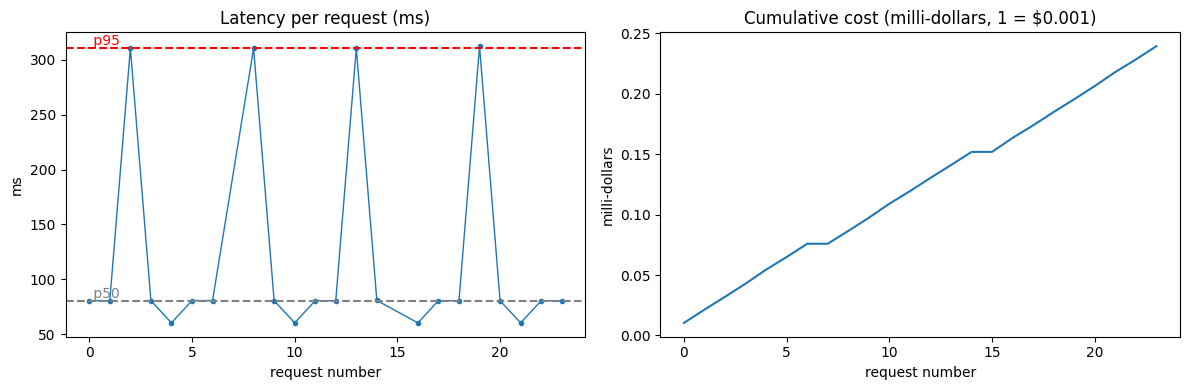

saved dashboard.png


In [7]:
def plot_dashboard(m, path="dashboard.png"):
    try:
        import matplotlib; matplotlib.use("Agg")
        import matplotlib.pyplot as plt
    except ImportError:
        print("matplotlib not installed: skipping charts (the text dashboard above has the same numbers)"); return None
    reqs, s = m["requests"], m["summary"]
    fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
    ok = [(i, r["latency_ms"]) for i, r in enumerate(reqs) if r["status"] == "ok"]
    a.plot([i for i, _ in ok], [v for _, v in ok], marker="o", ms=3, lw=1)
    a.axhline(s["p50_ms"], ls="--", c="gray"); a.axhline(s["p95_ms"], ls="--", c="red")
    a.text(0, s["p50_ms"], " p50", va="bottom", color="gray"); a.text(0, s["p95_ms"], " p95", va="bottom", color="red")
    a.set_title("Latency per request (ms)"); a.set_xlabel("request number"); a.set_ylabel("ms")
    run, cum = 0.0, []
    for r in reqs: run += r["cost_usd"]; cum.append(run * 1000)
    b.plot(range(len(cum)), cum); b.set_title("Cumulative cost (milli-dollars, 1 = $0.001)")
    b.set_xlabel("request number"); b.set_ylabel("milli-dollars")
    fig.tight_layout(); fig.savefig(path, dpi=110)
    try:
        from IPython.display import display; display(fig)
    except Exception: pass
    plt.close(fig); print("saved", path); return path

chart_path = plot_dashboard(metrics)

## Cell 7: The release gate (the CI idea)
Before a new version goes live, an automated check compares the measured numbers with limits (SLOs) and passes or fails. Here the limits are set from today's numbers with some headroom; in real life you choose them from what your users and budget need.

In [8]:
def slo_check(summary, slo):
    """Returns a list of failed checks. Empty list = release allowed."""
    fails = []
    if summary["p95_ms"] > slo["p95_ms"]:                        fails.append(f"p95 latency {summary['p95_ms']:.0f} ms > {slo['p95_ms']:.0f} ms")
    if summary["cost_per_request"] > slo["cost_per_request"]:    fails.append(f"cost per request ${summary['cost_per_request']:.6f} > ${slo['cost_per_request']:.6f}")
    if summary["errors"] / max(1, summary["total"]) > slo["error_rate"]: fails.append(f"error rate {summary['errors']}/{summary['total']} > {slo['error_rate']:.0%}")
    return fails

s = metrics["summary"]
SLO = {"p95_ms": s["p95_ms"] * 1.5, "cost_per_request": s["cost_per_request"] * 1.5, "error_rate": 0.0}
fails = slo_check(s, SLO)
print("SLO limits:", {k: round(v, 6) for k, v in SLO.items()})
print("RELEASE GATE:", "PASS" if not fails else "FAIL " + "; ".join(fails))

SLO limits: {'p95_ms': 465.879321, 'cost_per_request': 1.6e-05, 'error_rate': 0.0}
RELEASE GATE: PASS


## Cell 8: Tests
One `check(...)` per idea. Each one is short, so it is easy to read, change or add to.

In [9]:
def check(name, condition):
    print(("PASS  " if condition else "FAIL  ") + name)
    assert condition, name

MOCK = BACKEND == "mock"
def metrics_now(): return http("GET", "/metrics")[1]

# 1. The service is live
status, health = http("GET", "/health")
check("1. service is live: /health answers ok with a name and a version", status == 200 and health["status"] == "ok" and health["version"])

# 2. The endpoint contract
status, resp = http("POST", "/v1/agent:invoke", {"message": "Where is order A100?"})
check("2. invoke returns a reply, a request id, token usage, a cost and a latency",
      status == 200 and resp["reply"] and resp["request_id"] and resp["usage"]["input_tokens"] > 0
      and resp["usage"]["output_tokens"] > 0 and resp["cost_usd"] > 0 and resp["latency_ms"] > 0)

# 3. The agent works
check("3. the agent answers correctly: order A100 is 'shipped'", "shipped" in resp["reply"].lower())

# 4. The endpoint refuses bad requests politely
check("4. malformed body -> HTTP 400, unknown route -> HTTP 404",
      http("POST", "/v1/agent:invoke", b"not json")[0] == 400 and http("POST", "/nope", {"message": "x"})[0] == 404)

# 5. Guardrail: oversized input is refused BEFORE any model is called (so it costs nothing)
calls_before, total_before = MODEL_CALLS[0], metrics_now()["summary"]["total"]
status, resp = http("POST", "/v1/agent:invoke", {"message": "x" * 500})
last = metrics_now()["requests"][-1]
check("5. input guardrail: a 500-character message gets HTTP 422, makes no model call and costs $0",
      status == 422 and MODEL_CALLS[0] == calls_before and last["cost_usd"] == 0 and last["status"] == "rejected_input"
      and metrics_now()["summary"]["total"] == total_before + 1)

# 6. Guardrail: budget
old_budget = CONFIG["budget_usd"]; CONFIG["budget_usd"] = 0.0
calls_before = MODEL_CALLS[0]
status, resp = http("POST", "/v1/agent:invoke", {"message": "Where is order A100?"})
CONFIG["budget_usd"] = old_budget
check("6. budget guardrail: once the budget is used up the endpoint answers HTTP 429 and calls no model",
      status == 429 and MODEL_CALLS[0] == calls_before)
check("6b. ...and works again when the budget is restored", http("POST", "/v1/agent:invoke", {"message": "Where is order A100?"})[0] == 200)

# 7. The after-hook records every request, including refused ones
m = metrics_now(); n0 = m["summary"]["total"]
for msg in ["Where is A200?", "y" * 450, "Hello"]: http("POST", "/v1/agent:invoke", {"message": msg})
m2 = metrics_now()
check("7. every request is counted: 3 sent (2 normal, 1 refused) -> metrics total grows by exactly 3",
      m2["summary"]["total"] == n0 + 3 and [r["status"] for r in m2["requests"][-3:]] == ["ok", "rejected_input", "ok"])

# 8. Cost arithmetic, recomputed independently
reqs = m2["requests"]
recomputed = sum(r["in_tokens"] * PRICE_IN_PER_M / 1e6 + r["out_tokens"] * PRICE_OUT_PER_M / 1e6 for r in reqs)
check("8. cost is right: dashboard total equals tokens x price recomputed from scratch",
      abs(m2["summary"]["total_cost"] - recomputed) < 1e-12 and m2["summary"]["in_tokens"] == sum(r["in_tokens"] for r in reqs))

# 9. Latency statistics, recomputed independently
lat = sorted(r["latency_ms"] for r in reqs if r["status"] == "ok")
k = max(0, math.ceil(0.95 * len(lat)) - 1)
check("9. latency stats are right: p50 <= p95 <= max, and p95 equals the value recomputed from the raw records",
      m2["summary"]["p50_ms"] <= m2["summary"]["p95_ms"] <= m2["summary"]["max_ms"] and abs(m2["summary"]["p95_ms"] - lat[k]) < 1e-9)

# 10. The dashboard finds the slow part
slow = [r["tool_ms"] for r in reqs if r["order_id"] == "A300" and r["status"] == "ok"]
fast = [r["tool_ms"] for r in reqs if r["order_id"] in ("A100", "A200") and r["status"] == "ok"]
print(f"   average tool time: A300 {sum(slow)/len(slow):.0f} ms vs A100/A200 {sum(fast)/len(fast):.0f} ms" if slow and fast else "   no A300 traffic")
check("10. the dashboard exposes the slow spot: requests for A300 spend much longer in the tool (fake back-end)",
      not MOCK or (slow and fast and sum(slow) / len(slow) > 3 * sum(fast) / len(fast)))

# 11. The release gate works in both directions
s = metrics_now()["summary"]
ok_gate = slo_check(s, {"p95_ms": s["p95_ms"] * 1.5, "cost_per_request": s["cost_per_request"] * 1.5, "error_rate": 0.0})
bad_gate = slo_check(s, {"p95_ms": s["p95_ms"] * 0.5, "cost_per_request": s["cost_per_request"] * 0.5, "error_rate": 0.0})
check("11. release gate: passes with headroom, FAILS (naming latency and cost) when limits are tightened",
      ok_gate == [] and len(bad_gate) == 2 and "p95" in bad_gate[0] and "cost" in bad_gate[1])

# 12. The dashboard artefacts exist
check("12. the chart file was written (or matplotlib is missing and the text dashboard stands in)",
      chart_path is None or os.path.getsize(chart_path) > 5000)

undeploy()
print("\nOutcome met: the agent is live behind an endpoint, with guardrails, hooks, and cost and latency dashboards.")

PASS  1. service is live: /health answers ok with a name and a version
PASS  2. invoke returns a reply, a request id, token usage, a cost and a latency
PASS  3. the agent answers correctly: order A100 is 'shipped'
PASS  4. malformed body -> HTTP 400, unknown route -> HTTP 404
PASS  5. input guardrail: a 500-character message gets HTTP 422, makes no model call and costs $0
PASS  6. budget guardrail: once the budget is used up the endpoint answers HTTP 429 and calls no model
PASS  6b. ...and works again when the budget is restored
PASS  7. every request is counted: 3 sent (2 normal, 1 refused) -> metrics total grows by exactly 3
PASS  8. cost is right: dashboard total equals tokens x price recomputed from scratch
PASS  9. latency stats are right: p50 <= p95 <= max, and p95 equals the value recomputed from the raw records
   average tool time: A300 251 ms vs A100/A200 20 ms
PASS  10. the dashboard exposes the slow spot: requests for A300 spend much longer in the tool (fake back-end)
PASS 